# c2 · Step 2: Evaluation setup

Decides, before any model exists: the **primary metric** (picks models/checkpoints), the **secondary metrics**
(always reported), the **noise level** (what counts as a real difference), the **val protocol** and the
**severity rule** for the step-10 threshold. All metrics are computed by `lib/evaluation.py::evaluate`, which
every later notebook uses.

Evaluation set: **clean val** (832 images; c1 removed 60 copies of train images).

In [1]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef,
                             cohen_kappa_score)
from lib.data import CLASSES, NO_TUMOR, SEED, list_split, excluded_paths, DATA_ROOT
from lib.evaluation import wilson, bootstrap_ci

def labels(split, clean=True):
    ex = excluded_paths() if clean else set()
    return np.array([c for p, c in list_split(split) if str(p.relative_to(DATA_ROOT)) not in ex])
y_train, y_val = labels("train"), labels("val")
print("clean val class counts:", dict(zip(CLASSES, np.bincount(y_val))))

clean val class counts: {'glioma': np.int64(312), 'meningioma': np.int64(216), 'no_tumor': np.int64(96), 'pituitary': np.int64(208)}


## 1. Primary metric: options

| Metric | What it measures |
|---|---|
| accuracy | share of correct predictions |
| balanced accuracy | mean of per-class recall |
| macro-F1 | mean of per-class F1 (recall and precision) |
| weighted-F1 | per-class F1 weighted by class size |
| MCC / Cohen's κ | correlation between prediction and truth, corrected for chance |

Two tests: what do **dumb classifiers** score, and how does each metric react to the **same number of errors
placed differently**?

In [2]:
METRICS = {
    "accuracy": accuracy_score,
    "balanced acc": balanced_accuracy_score,
    "macro F1": lambda t, p: f1_score(t, p, average="macro", zero_division=0),
    "weighted F1": lambda t, p: f1_score(t, p, average="weighted", zero_division=0),
    "MCC": matthews_corrcoef,
    "kappa": cohen_kappa_score,
}
rows = {}
for name, strat in [("predict largest", "most_frequent"), ("proportional random", "stratified"),
                    ("uniform random", "uniform")]:
    scores = []
    for s in range(200 if strat != "most_frequent" else 1):  # average random guessers over 200 seeds
        clf = DummyClassifier(strategy=strat, random_state=s).fit(np.zeros((len(y_train), 1)), y_train)
        p = clf.predict(np.zeros((len(y_val), 1)))
        scores.append({m: f(y_val, p) for m, f in METRICS.items()})
    rows[name] = pd.DataFrame(scores).mean()
display(pd.DataFrame(rows).T.round(3))

,accuracy,balanced acc,macro F1,weighted F1,MCC,kappa
predict largest,0.375,0.250,0.136,0.205,0.000,0.000
proportional random,0.280,0.250,0.250,0.282,-0.000,-0.000
uniform random,0.251,0.251,0.242,0.260,0.002,0.001


**Result.** (Random guessers are averaged over 200 seeds.)
* **Accuracy** gives the *do-nothing* classifier its best score (0.375). That rules it out.
* **Weighted-F1** prefers proportional guessing (0.282), so it is biased by class size in the same way.
* **Balanced accuracy, MCC and κ** score every dumb classifier at exactly chance (0.25 / 0 / 0), whatever the
  strategy, so they have a fixed "no skill" reference. Macro-F1's chance level depends on the guessing strategy
  (0.14-0.25).

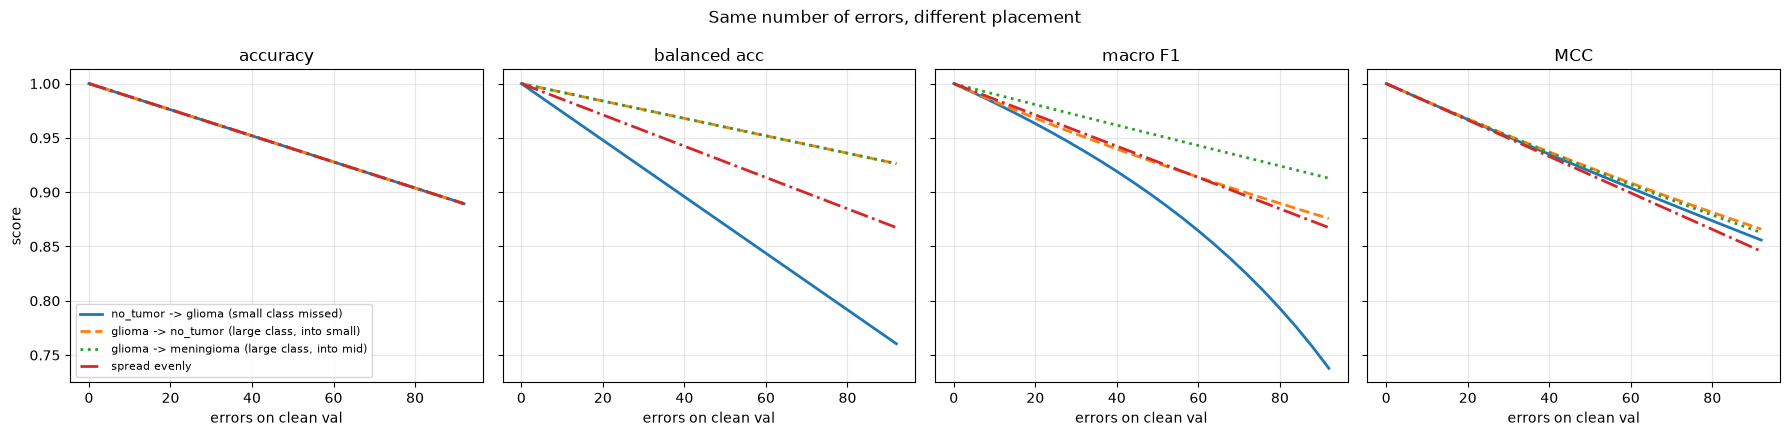

In [3]:
def corrupt(errors):
    y_pred = y_val.copy()
    for t, w, n in errors:
        idx = np.where((y_val == t) & (y_pred == t))[0][:n]
        y_pred[idx] = w
    return y_pred

G, M, NT, P = range(4)
def scenarios(n):
    return {"no_tumor -> glioma (small class missed)": [(NT, G, n)],
            "glioma -> no_tumor (large class, into small)": [(G, NT, n)],
            "glioma -> meningioma (large class, into mid)": [(G, M, n)],
            "spread evenly": [(c, (c + 1) % 4, n // 4) for c in range(4)]}
ns = np.arange(0, 93, 4)
show = ["accuracy", "balanced acc", "macro F1", "MCC"]
res = {m: {s: [] for s in scenarios(0)} for m in show}
for n in ns:
    for s, e in scenarios(n).items():
        p = corrupt(e)
        for m in show:
            res[m][s].append(METRICS[m](y_val, p))
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), sharey=True)
for ax, m in zip(axes, show):
    for (s, v), ls in zip(res[m].items(), ["-", "--", ":", "-."]):
        ax.plot(ns, v, ls=ls, lw=2, label=s)
    ax.set(title=m, xlabel="errors on clean val"); ax.grid(alpha=0.3)
axes[0].set_ylabel("score"); axes[0].legend(fontsize=8, loc="lower left")
plt.suptitle("Same number of errors, different placement"); plt.tight_layout(); plt.show()

**Result.**
* **Accuracy and MCC barely notice where errors are.** All lines nearly overlap, so they don't protect the
  small class.
* **Balanced accuracy** is linear. A missed no_tumor image costs 312/96 ≈ 3.3x as much as a missed glioma image,
  because each error costs 1/(4·n_class). It ignores *where* the error lands: "glioma → no_tumor" and
  "glioma → meningioma" are the same line.
* **Macro-F1** also penalises errors *landing in* the small class (orange below green), through no_tumor's
  precision. Its penalty is non-linear and grows faster as no_tumor recall falls.

**Decision: balanced accuracy is the primary metric.**
1. Its fixed chance level (0.25) makes it easy to interpret.
2. It is linear and recall-based, so its noise is easy to reason about. It doesn't depend on class prevalence,
   which matches the sensitivity/ROC framing of step 10.
3. Its blind spot (it doesn't care *which* wrong class is predicted) is exactly the tumour → no_tumor error.
   That error is handled explicitly by the step-10 threshold and the reported tumour sensitivity, not by the
   selection metric.

**Secondary metrics (always reported):** macro-F1 (catches false alarms *into* small classes), per-class recall,
confusion matrix, tumour-vs-no-tumour ROC AUC, tumour sensitivity and specificity.

## 2. Noise: how big must a difference be?
Three sources of noise. (a) and (b) are computed here, (c) needs a trained model and is measured in c4.

* (a) **per-class recall** on a fixed val set: Wilson 95 % interval
* (b) **balanced accuracy** on a fixed val set: bootstrap of a simulated classifier
* (c) **retraining** the same config with another seed

In [4]:
n_cls = np.bincount(y_val)
rows = {}
for r in [0.80, 0.90, 0.95]:
    rows[f"recall {r:.2f}"] = {c: "±{:.1f}".format(50 * np.subtract(*wilson(round(r * n), n)[::-1]) * 2 / 2)
                               for c, n in zip(CLASSES, n_cls)}
print("Wilson 95 % interval half-width, in percentage points:")
display(pd.DataFrame(rows).T)

Wilson 95 % interval half-width, in percentage points:


,glioma,meningioma,no_tumor,pituitary
recall 0.80,±4.4,±5.3,±7.9,±5.4
recall 0.90,±3.3,±4.1,±6.2,±4.1
recall 0.95,±2.5,±3.0,±4.7,±3.0


In [5]:
rng = np.random.default_rng(SEED)
rows = {}
for acc in [0.80, 0.90, 0.95]:
    p = y_val.copy()
    wrong = rng.random(len(p)) > acc                      # errors spread at random over all classes
    p[wrong] = (p[wrong] + rng.integers(1, 4, wrong.sum())) % 4
    lo, hi = bootstrap_ci(y_val, p, n_boot=2000, seed=SEED)
    rows[f"~{acc:.2f} correct"] = {"bal_acc": balanced_accuracy_score(y_val, p), "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                                   "half-width (pp)": round(50 * (hi - lo), 1)}
display(pd.DataFrame(rows).T)

,bal_acc,95% CI,half-width (pp)
~0.80 correct,0.818309,"[0.790, 0.846]",2.8
~0.90 correct,0.909077,"[0.889, 0.929]",2.0
~0.95 correct,0.943153,"[0.925, 0.961]",1.8


**Result.**
* **Per class:** no_tumor (96 images) is by far the noisiest. At 90 % recall its 95 % interval is about ±6 pp;
  the other classes are about ±3-4 pp.
* **Balanced accuracy** of one model on clean val: about ±2 pp (95 % CI half-width) at the 0.9 level.
* Comparing two models on the *same* images is less noisy than two independent intervals suggest, because the
  shared noise cancels. That is why comparisons use the **paired bootstrap** (`lib.evaluation.paired_bootstrap`).

**Decision: the "meaningful difference" rule** (seed noise σ_seed is measured in c4):
* A change is **adopted** if Δ balanced accuracy > 2·σ_seed **and** the paired bootstrap gives P(not better) < 0.05.
* Otherwise it is a **tie**. Ties go to the simpler, cheaper or more standard option.
* For decisions that shape the final model (architecture, regularisation), close calls get 2 extra seeds and
  the means are compared.

## 3. Binary view and prevalence
For the tumour vs no-tumour decision: does precision (PPV) transfer from this dataset to practice?
Example classifier with sensitivity 0.98 and specificity 0.90, evaluated at the dataset's tumour prevalence and at
lower prevalences (Bayes' rule).

In [6]:
sens, spec = 0.98, 0.90
prev_data = (y_val != NO_TUMOR).mean()
rows = {}
for name, prev in [("this dataset", prev_data), ("specialist referral (assumed)", 0.30),
                   ("routine headache MRI (assumed)", 0.01)]:
    ppv = sens * prev / (sens * prev + (1 - spec) * (1 - prev))
    npv = spec * (1 - prev) / (spec * (1 - prev) + (1 - sens) * prev)
    rows[name] = {"tumour prevalence": prev, "sensitivity": sens, "specificity": spec, "PPV": ppv, "NPV": npv}
display(pd.DataFrame(rows).T.round(3))

,tumour prevalence,sensitivity,specificity,PPV,NPV
this dataset,0.885,0.98,0.9,0.987,0.854
specialist referral (assumed),0.300,0.98,0.9,0.808,0.991
routine headache MRI (assumed),0.010,0.98,0.9,0.090,1.000


**Result.** The same classifier (sensitivity 0.98, specificity 0.90) has a PPV of 0.987 on this dataset, but
0.81 at 30 % prevalence and **0.09** at 1 %. Sensitivity and specificity do not change.

**Decision.** For the tumour decision, report **sensitivity, specificity and ROC AUC**. They transfer to other
prevalences. Precision/PPV is only used as a diagnostic inside this dataset, never as a headline number. This
dataset has 88.5 % tumours; clinical practice usually has far fewer.

## 4. Val protocol

| Data | Used for | Never used for |
|---|---|---|
| **train** | fitting weights, normalisation statistics, class weights | any decision |
| **clean val** (832) | early stopping, checkpoint choice, every comparison in c4-c9, the step-10 threshold | fitting |
| **test** | one final run with everything frozen (official 889 and clean 833) | anything else |

**Not decided yet (needs a trained model):** what early stopping and checkpointing **monitor**.
* **val loss:** smooth, and rewards good probabilities (which step 10 needs). But it can rise from over-confidence
  while accuracy still improves.
* **val balanced accuracy:** the actual target, but a noisy step function that tends to pick a lucky epoch.

Both are logged every epoch. The choice is made in **c4** from the initial model's curves.

**Test set:** this run does **not** touch it. All selection is on clean val.

## 5. Severity rule for the threshold (step 10)

Options for picking the cutoff t on P(tumour) = 1 - P(no_tumor):

| Rule | Meaning | Verdict |
|---|---|---|
| argmax | predict the most likely class | implicitly treats all errors as equal |
| Youden's J | maximise sensitivity + specificity - 1 | equal cost for FN and FP, so rejected |
| min expected cost | minimise c_FN·FN + c_FP·FP for an assumed ratio | needs a cost ratio nobody here can justify precisely |
| **target sensitivity** | highest t with val tumour sensitivity ≥ target | explicit and easy to explain |

**Decision:** target tumour sensitivity **≥ 0.98** on clean val. That means at most 14 of 736 tumour images missed.
Specificity is reported at that cutoff, with Wilson intervals for both. A 10:1 cost-ratio cutoff is shown next to
it as a sensitivity analysis, so the reader can see how much the choice of rule matters.

## Decisions

| Decision | Choice | Evidence |
|---|---|---|
| Primary metric | **balanced accuracy** | fixed chance level; linear; protects small classes (sections 1-2) |
| Secondary metrics | macro-F1, per-class recall, confusion matrix, tumour AUC, sensitivity/specificity | section 1, section 3 |
| Not reported as headline | accuracy, weighted-F1, precision/PPV | dumb-classifier test, prevalence test |
| Meaningful difference | Δ > 2·σ_seed and paired-bootstrap P < 0.05; ties go to the simpler option | section 2 (σ_seed in c4) |
| Evaluation set | clean val for everything; test once at the end | c1, section 4 |
| Early-stopping monitor | decided in c4 from the curves | section 4 |
| Threshold rule | tumour sensitivity ≥ 0.98 on val | section 5 |